# Este notebook está uma bagunça!

3-Nov-2026: Pegando os dados em que o tempo foi homegeinizado, aplicar filtro de média móvel para uniformizar com a IEN

--> Aumenta o intervalo das classes do IEN!

In [1]:
import matplotlib.pyplot as plt
from dateutil.parser import parse
import datetime
import numpy as np
import pickle

import matplotlib.dates as mdates

In [2]:
path = r'd:\GUTO\Academia\Curso_Analise_de_Dados\Curso2026\Vazao\\'
arquivo = 'Vazoes_camaqua.txt'

with open(path + arquivo) as io:
    linhas = io.readlines()

len(linhas)

757

In [3]:
hdr = linhas[15].split(';')

for i, h in enumerate(hdr):
    print(i, h)

0 EstacaoCodigo
1 NivelConsistencia
2 Data
3 Hora
4 MediaDiaria
5 MetodoObtencaoVazoes
6 Maxima
7 Minima
8 Media
9 DiaMaxima
10 DiaMinima
11 MaximaStatus
12 MinimaStatus
13 MediaStatus
14 MediaAnual
15 MediaAnualStatus
16 Vazao01
17 Vazao02
18 Vazao03
19 Vazao04
20 Vazao05
21 Vazao06
22 Vazao07
23 Vazao08
24 Vazao09
25 Vazao10
26 Vazao11
27 Vazao12
28 Vazao13
29 Vazao14
30 Vazao15
31 Vazao16
32 Vazao17
33 Vazao18
34 Vazao19
35 Vazao20
36 Vazao21
37 Vazao22
38 Vazao23
39 Vazao24
40 Vazao25
41 Vazao26
42 Vazao27
43 Vazao28
44 Vazao29
45 Vazao30
46 Vazao31
47 Vazao01Status
48 Vazao02Status
49 Vazao03Status
50 Vazao04Status
51 Vazao05Status
52 Vazao06Status
53 Vazao07Status
54 Vazao08Status
55 Vazao09Status
56 Vazao10Status
57 Vazao11Status
58 Vazao12Status
59 Vazao13Status
60 Vazao14Status
61 Vazao15Status
62 Vazao16Status
63 Vazao17Status
64 Vazao18Status
65 Vazao19Status
66 Vazao20Status
67 Vazao21Status
68 Vazao22Status
69 Vazao23Status
70 Vazao24Status
71 Vazao25Status
72 Vazao26Statu

In [31]:
mes_31 = [1, 3, 5, 7, 8, 10, 12]
mes_30 = [4, 6, 9, 11]

tempo = []
vazao_diaria = []
for linha in linhas[16:]:
    # linha = linhas[16]
    linha = linha.replace('"','').replace(',','.').split(';')
    
    campo_data = linha[2].split('/')
    mes = int(campo_data[1])
    ano = int(campo_data[2])

    campos_vazao = linha[16:47]

    if mes in mes_31:
        vazao_diaria = vazao_diaria + campos_vazao
        dias_mes = np.arange(1, 32)
        tempo_dt = []
        for d in dias_mes:
            tempo_dt.append(datetime.datetime(ano, mes, d))
        tempo = tempo + tempo_dt

    elif mes in mes_30:
        vazao_diaria = vazao_diaria + campos_vazao[:30]
        dias_mes = np.arange(1, 31)
        tempo_dt = []
        for d in dias_mes:
            tempo_dt.append(datetime.datetime(ano, mes, d))
        tempo = tempo + tempo_dt

    else:
        if ano%4 == 0:
            nd = 29
        else:
            nd = 28

        vazao_diaria = vazao_diaria + campos_vazao[:nd]
        dias_mes = np.arange(1, nd+1)
        tempo_dt = []
        for d in dias_mes:
            tempo_dt.append(datetime.datetime(ano, mes, d))
        tempo = tempo + tempo_dt

for i in range(len(vazao_diaria)):
    if vazao_diaria[i] == '':
        vazao_diaria[i] = np.nan
    else:
        vazao_diaria[i] = float(vazao_diaria[i])
    

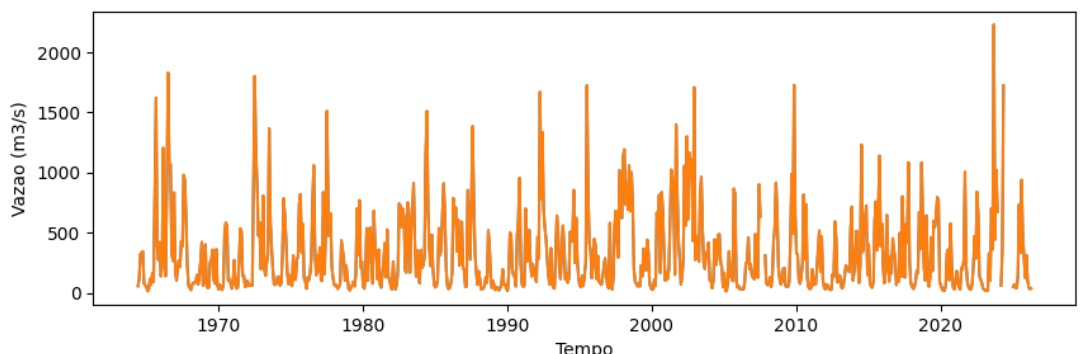

(np.float64(-1826.0), np.float64(-1096.0))

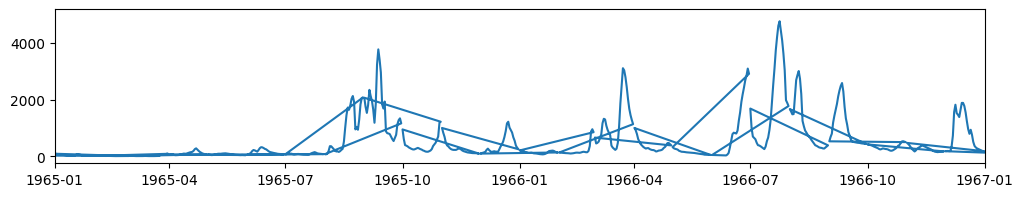

In [36]:
plt.figure(figsize=(12,2))
plt.plot(tempo, vazao_diaria)
plt.xlim(datetime.datetime(1965,1,1), datetime.datetime(1967,1,1))

(np.float64(365.0), np.float64(1826.0))

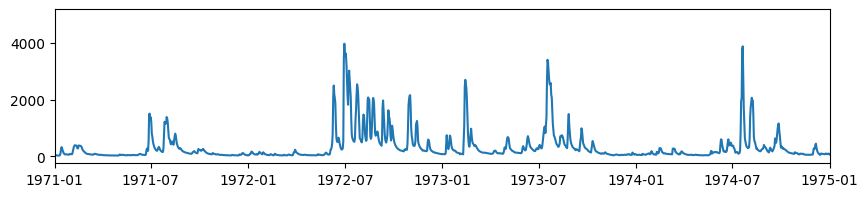

In [57]:
tempo_n = mdates.date2num(tempo)

tempo_vazao = np.column_stack((tempo_n, vazao_diaria))

x = tempo_vazao[tempo_vazao[:, 0].argsort()]

tempo_2 = mdates.num2date(x[:,0])
vazao_2 = x[:,1]

plt.figure(figsize=(10,2))
plt.plot(tempo_2, vazao_2)
plt.xlim(datetime.datetime(1971,1,1), datetime.datetime(1975,1,1))

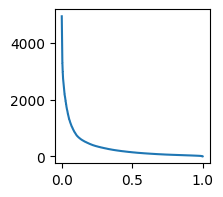

In [54]:
vazao_3 = vazao_2[~np.isnan(vazao_2)]

vazao_sort = np.flip(np.sort(vazao_3))
vazao_prob = np.linspace(0, 1, len(vazao_sort))

plt.figure(figsize=(2,2))
plt.plot(vazao_prob, vazao_sort)

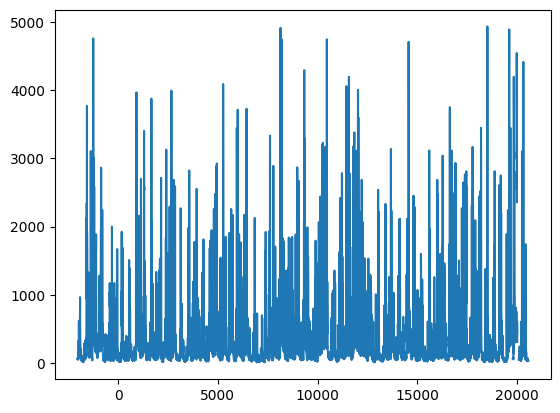

In [44]:
plt.plot(x[:,0], x[:,1])

In [29]:
740*31

22940

In [22]:
x = campos_vazao[:28]
for i, v in enumerate(x):
    print(i, v)

0 39.4445
1 34.7865
2 32.4258
3 29.8515
4 28.0061
5 26.8158
6 28.9198
7 35.8295
8 57.9769
9 53.8272
10 65.8278
11 55.1894
12 48.1639
13 42.1032
14 37.9729
15 36.5355
16 37.6103
17 37.9729
18 35.4797
19 33.7622
20 32.4258
21 31.4451
22 32.0968
23 31.4451
24 33.7622
25 36.5355
26 34.1015
27 31.7699


# Prototipagem de manipulação da string

In [8]:
linha = linhas[230]
linha = linha.replace('"','').replace(',','.').split(';')

campo_data = linha[2].split('/')
mes = int(campo_data[1])
ano = int(campo_data[2])
media = float(linha[8])
tempo_dt = datetime.datetime(ano, mes, 15)

print(mes, ano, media)
print(tempo_dt, media)

6 2008 429.9292
2008-06-15 00:00:00 429.9292


In [9]:
linha[2]

'01/06/2008'

In [10]:
linha[6]

'1276.5927'

In [11]:
linha[6].replace('"','')

'1276.5927'

In [12]:
linha[6].replace(',','.')

'1276.5927'

In [13]:
float(linha[6].replace(',','.').replace('"',''))

1276.5927

# Pegando os dados médios mensais

In [14]:
tempo = []
vazao_media_mensal = []
for linha in linhas[16:]:
    # linha = linhas[16]
    linha = linha.replace('"','').replace(',','.').split(';')
    
    campo_data = linha[2].split('/')
    mes = int(campo_data[1])
    ano = int(campo_data[2])
    
    campo_8 = linha[8]
    if campo_8 == '':
        media = np.nan
    else:
        media = float(campo_8)
    
    tempo_dt = datetime.datetime(ano, mes, 15)

    tempo.append(tempo_dt)
    vazao_media_mensal.append(media)

### Os dados estão em ordem cronológica inversa...!
### Coloca or dados em ordem correta!!!!
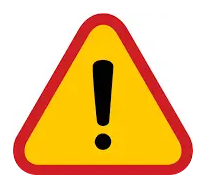

In [15]:
tempo = np.flip(tempo)
vazao_media_mensal = np.flip(vazao_media_mensal)

# Inspeciona o tempo para verificar se há falhas
### Há uma falha de 2 meses em 2007 (agosto e setembro)

(np.float64(12418.0), np.float64(15340.0))

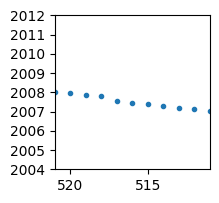

In [16]:
plt.figure(figsize=(2,2))
plt.plot(tempo,'.')
plt.xlim(741-220, 741-230)
plt.ylim(datetime.date(2004,1,1), datetime.date(2012,1,1))

In [17]:
type(tempo)

numpy.ndarray

In [18]:
tempo.shape

(741,)

In [19]:
741 - 225

516

In [20]:
tempo[516:521]

array([datetime.datetime(2007, 6, 15, 0, 0),
       datetime.datetime(2007, 7, 15, 0, 0),
       datetime.datetime(2007, 10, 15, 0, 0),
       datetime.datetime(2007, 11, 15, 0, 0),
       datetime.datetime(2007, 12, 15, 0, 0)], dtype=object)

In [21]:
tempo_1 = tempo[:518]
tempo_2 = tempo[518:]
tempo_meio = [datetime.datetime(2007, 8,15, 0), datetime.datetime(2007, 9, 15, 0)]

# tempo_preenchido = tempo_1.tolist() + tempo_meio + tempo_2.tolist()
tempo_preenchido = np.concatenate((tempo_1, tempo_meio, tempo_2))

print(tempo_1[-1])
print(tempo_2[0])

2007-07-15 00:00:00
2007-10-15 00:00:00


In [22]:
plt.figure(figsize=(2,2))
plt.plot(tempo_preenchido_n)


NameError: name 'tempo_preenchido_n' is not defined

<Figure size 200x200 with 0 Axes>

- Deu erro na interpolação da vazao... possivelmente por causa da ordem cronológica inversal que os dados estão orgininalmnete... os dados foram invertidos (flip)...! --- o 'f' nas variáveis"

- O notebook foi refeito e os dados foram corrigidos cronologicamente no início!

In [23]:
tempo_n = mdates.date2num(tempo)
tempo_preenchido_n = mdates.date2num(tempo_preenchido)

vazao_media_mensal_i = np.interp(tempo_preenchido_n, tempo_n, vazao_media_mensal)

In [24]:
print(len(tempo_n))
print(len(tempo_preenchido_n))

741
743


Text(0.5, 0, 'Tempo')

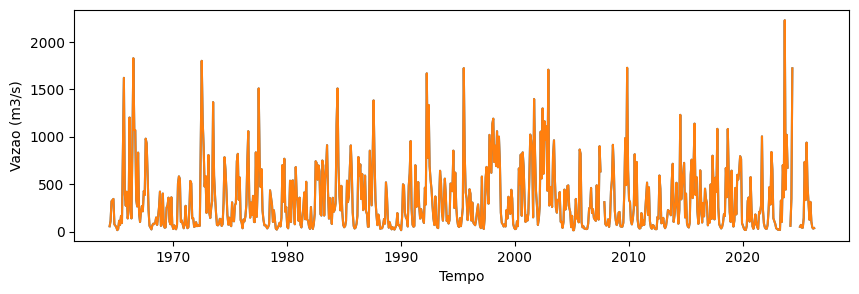

In [25]:
plt.figure(figsize=(10,3))
plt.plot(tempo, vazao_media_mensal)
plt.plot(tempo_preenchido, vazao_media_mensal_i)
plt.ylabel('Vazao (m3/s)')
plt.xlabel('Tempo')

# 3-Nov-2026 - Aplicação de média móvel

In [26]:
# vaz a média móvel para 'vazao_media_mensal_i'

tempo_filtrado = []
vazao_filtrada = []

for i in range(1, len(tempo_preenchido)-1):
    calcula_media = (
                    vazao_media_mensal_i[i-1] +
                    vazao_media_mensal_i[i] +
                    vazao_media_mensal_i[i+1]
                    ) / 3

    vazao_filtrada.append(calcula_media)
    tempo_filtrado.append(tempo_preenchido[i])

vazao_filtrada = np.array(vazao_filtrada)
tempo_filtrado = np.array(tempo_filtrado)

print(len(vazao_filtrada), len(tempo_filtrado))

741 741


In [27]:
tempo_preenchido[0-1]

datetime.datetime(2026, 4, 15, 0, 0)

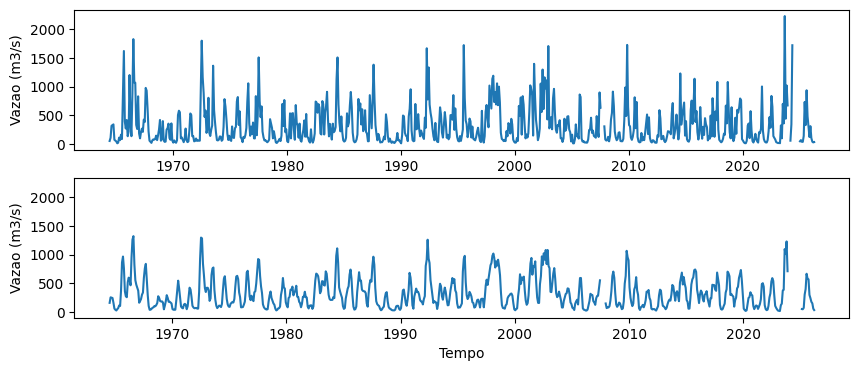

In [28]:
fig, axs = plt.subplots(2, figsize=(10,4))
axs[0].plot(tempo_preenchido, vazao_media_mensal_i)
ylim = axs[0].get_ylim()
axs[1].plot(tempo_filtrado, vazao_filtrada)
axs[1].set_ylim(ylim)
for ax in axs:
    ax.set_ylabel('Vazao (m3/s)')
    ax.set_xlabel('Tempo')

# TESTE: Problema no caso de desordem cronológica

In [29]:
lista_datas = [datetime.datetime(2026, 9, 29, 12),
               datetime.datetime(2026, 9, 25, 15),
               datetime.datetime(2026, 9, 30, 20)]

lista_dados = [10, 5, 15]

lista_2 = sorted(lista_datas)
lista_2

[datetime.datetime(2026, 9, 25, 15, 0),
 datetime.datetime(2026, 9, 29, 12, 0),
 datetime.datetime(2026, 9, 30, 20, 0)]

In [30]:
datas_2, dados_2 = map(list, zip(*sorted(zip(lista_datas, lista_dados))))

print(datas_2)
print(dados_2)

[datetime.datetime(2026, 9, 25, 15, 0), datetime.datetime(2026, 9, 29, 12, 0), datetime.datetime(2026, 9, 30, 20, 0)]
[5, 10, 15]


In [31]:
x = tempo[0]
x.year

1964

In [32]:
anos = np.arange(1964, 2027)

vazao_media_anual = []

for ano in anos:

    acumula_vazao = []
    for i, data_mes in enumerate(tempo):

        if data_mes.year == ano:

            acumula_vazao.append(vazao_media_mensal[i])

    vazao_media_anual.append(np.nanmean(acumula_vazao))

In [33]:
print(len(vazao_media_mensal))
print(len(vazao_media_anual))

741
63


In [34]:
tempo[0]

datetime.datetime(1964, 5, 15, 0, 0)

In [35]:
tempo_ien_n[0]

1950.0833333333333

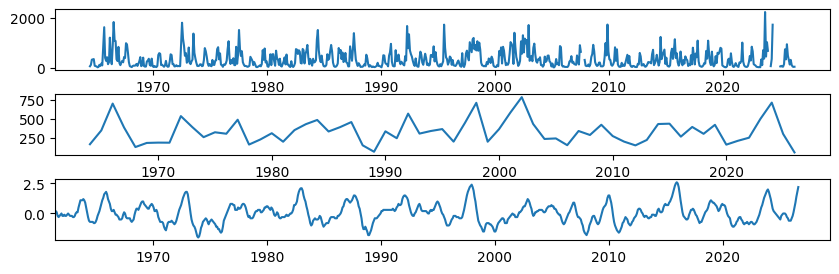

In [36]:
fig, axs = plt.subplots(3, figsize=(10,3))
axs[0].plot(tempo, vazao_media_mensal)
axs[1].plot(anos, vazao_media_anual)
xlim = axs[0].get_xlim()
axs[2].plot(tempo_ien, ien)
axs[2].set_xlim(xlim)
plt.subplots_adjust(hspace=.4)

# Sincronizando os dados de El Nino para os dados de Vazão
# Interpolação!

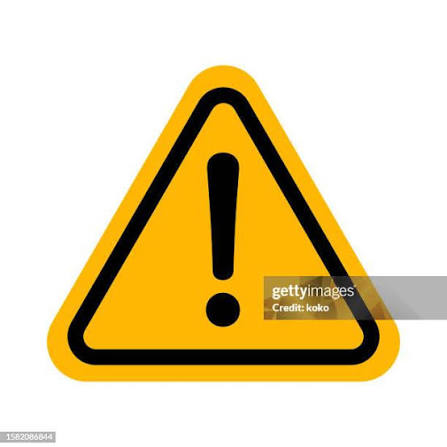
# Alterando para usar com os dados filtrados

In [37]:
tempo_vazao_n = mdates.date2num(tempo)
tempo_ien_n = mdates.date2num(tempo_ien)

ien_sinc = np.interp(tempo_vazao_n, tempo_ien_n, ien)

In [38]:
tempo_filtrado_n = mdates.date2num(tempo_filtrado)

ien_sinc_novo = np.interp(tempo_filtrado_n, tempo_ien_n, ien)

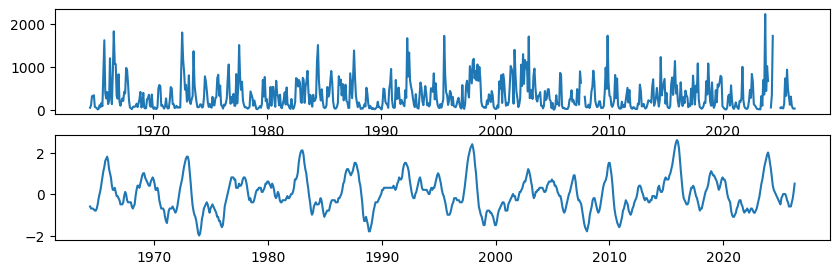

In [39]:
fig, axs = plt.subplots(2, figsize=(10,3))
axs[0].plot(tempo, vazao_media_mensal)
axs[1].plot(tempo, ien_sinc)

# Faz a curva de probabilidade de excedência

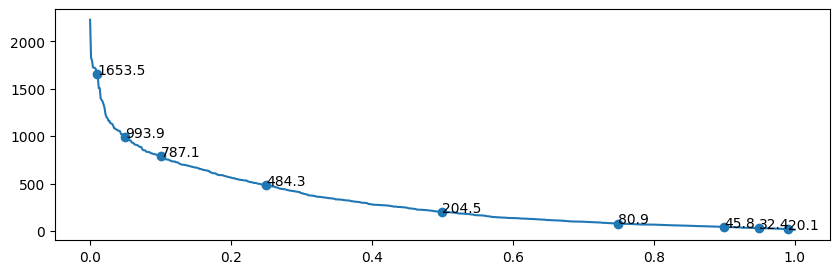

In [67]:
vmm = vazao_media_mensal[~np.isnan(vazao_media_mensal)]

percentis = [.01, .05, .1, .25, .5, .75, .9, .95, .99]

vmm_sort = np.flip(np.sort(vmm))
vmm_prob = np.linspace(0, 1, len(vmm_sort))

vmm_percentis = np.interp(percentis, vmm_prob, vmm_sort)

plt.figure(figsize=(10,3,))
plt.plot(vmm_prob, vmm_sort)
for i in range(len(vmm_percentis)):
    plt.plot(percentis[i], vmm_percentis[i], 'o', color='tab:blue')
    plt.text(percentis[i], vmm_percentis[i], str(vmm_percentis[i].round(1)))

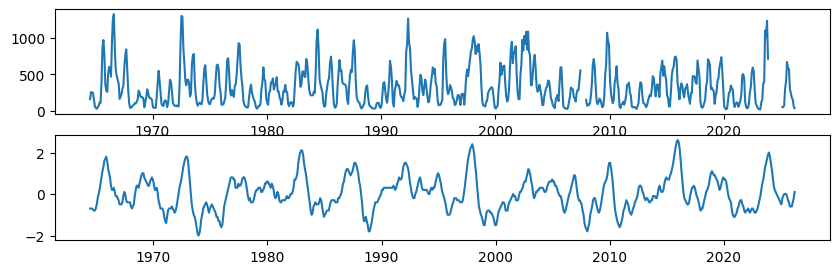

In [40]:
fig, axs = plt.subplots(2, figsize=(10,3))
axs[0].plot(tempo_filtrado, vazao_filtrada)
axs[1].plot(tempo_filtrado, ien_sinc_novo)

Text(0, 0.5, 'Vazao Mensal (m3/s)')

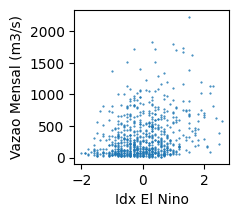

In [41]:
plt.figure(figsize=(2,2))
plt.plot(ien_sinc, vazao_media_mensal,'.', ms=1)
plt.xlabel('Idx El Nino')
plt.ylabel('Vazao Mensal (m3/s)')

Text(0, 0.5, 'Vazao Mensal (m3/s)')

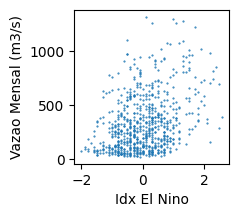

In [42]:
plt.figure(figsize=(2,2))
plt.plot(ien_sinc_novo, vazao_filtrada,'.', ms=1)
plt.xlabel('Idx El Nino')
plt.ylabel('Vazao Mensal (m3/s)')

In [43]:
print(type(vazao_media_mensal))

vmm = np.array(vazao_media_mensal)

<class 'numpy.ndarray'>


Text(0, 0.5, 'Vazao Mensal (m3/s)')

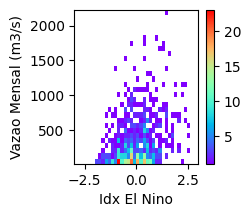

In [44]:
mask = np.isfinite(vmm) & np.isfinite(ien_sinc)

vmm_clean = vmm[mask]
ien_clean = ien_sinc[mask]

plt.figure(figsize=(2,2))
cb = plt.hist2d(ien_clean, vmm_clean, cmin=1, bins=30, cmap='rainbow')
plt.colorbar()
plt.xlim(-3, 3)
plt.xlabel('Idx El Nino')
plt.ylabel('Vazao Mensal (m3/s)')

# Achando a vazao média por classes de IEN

In [45]:
classes_ien = np.arange(-3, 3.5, .1)
centro_classes_ien = (classes_ien[1:] + classes_ien[:-1])/2

ien_vazao_ocorrencias = []
ien_vazao_media = []
ien_vazao_dp = []

ien_vazao_ocorrencias_novo = []
ien_vazao_media_novo = []
ien_vazao_dp_novo = []
for i in range(len(classes_ien) -1):

    idx = np.where( (ien_clean >= classes_ien[i]) & (ien_clean < classes_ien[i+1]) )[0]
    idx_2 = np.where( (ien_sinc_novo >= classes_ien[i]) & (ien_sinc_novo < classes_ien[i+1]) )[0]
    
    ien_vazao_ocorrencias.append(len(idx))
    ien_vazao_media.append(np.mean(vmm_clean[idx]))
    ien_vazao_dp.append(np.std(vmm_clean[idx]))   

    ien_vazao_ocorrencias_novo.append(len(idx_2))
    ien_vazao_media_novo.append(np.nanmean(vazao_filtrada[idx_2]))
    ien_vazao_dp_novo.append(np.nanstd(vazao_filtrada[idx_2]))   

C:\Python314\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Python314\Lib\site-packages\numpy\_core\_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Python314\Lib\site-packages\numpy\_core\_methods.py:222: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Python314\Lib\site-packages\numpy\_core\_methods.py:180: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\Python314\Lib\site-packages\numpy\_core\_methods.py:214: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\gutos\AppData\Local\Temp\ipykernel_12560\1948215430.py:21: RuntimeWarning: Mean of empty slice
  ien_vazao_media_novo.append(np.nanmean(vazao_filtrada[idx_2]))
C:\Python314\Lib\site-packages\

(-3.3200000000000003, 3.7200000000000064)

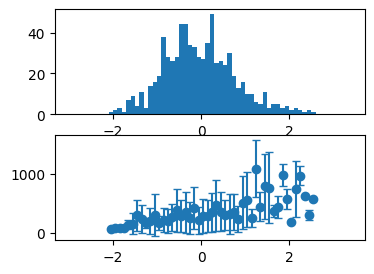

In [46]:
fig, axs = plt.subplots(2,1, figsize=(4,3))

axs[0].bar(centro_classes_ien, ien_vazao_ocorrencias, .1)
xlim= axs[0].get_xlim()
axs[1].errorbar(centro_classes_ien, ien_vazao_media, yerr=ien_vazao_dp, fmt="o", capsize=3)
axs[1].set_xlim(xlim)

(-3.3200000000000003, 3.7200000000000064)

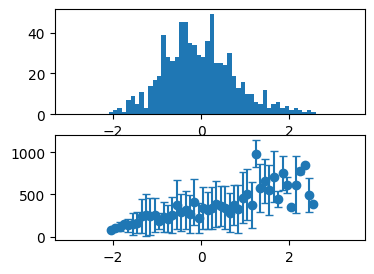

In [47]:
fig, axs = plt.subplots(2,1, figsize=(4,3))

axs[0].bar(centro_classes_ien, ien_vazao_ocorrencias_novo, .1)
xlim= axs[0].get_xlim()
axs[1].errorbar(centro_classes_ien, ien_vazao_media_novo, yerr=ien_vazao_dp_novo, fmt="o", capsize=3)
axs[1].set_xlim(xlim)

In [48]:
len(ien_vazao_media)

64

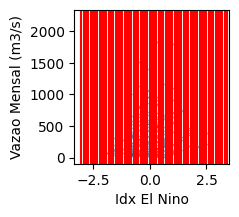

In [49]:
plt.figure(figsize=(2,2))
plt.plot(ien_sinc, vazao_media_mensal,'.', ms=1)
plt.xlabel('Idx El Nino')
plt.ylabel('Vazao Mensal (m3/s)')
for c in classes_ien:
    plt.axvline(c, color='r')

- Verificando a sobreposição do tempo de vazao e el nino

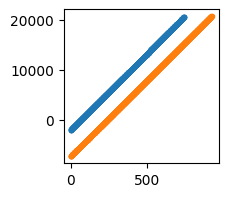

In [50]:
plt.figure(figsize=(2,2))
plt.plot(tempo_vazao_n,'.')
plt.plot(tempo_ien_n,'.')

In [51]:
tempo_vazao_n[0]

np.float64(-2057.0)

ValueError: x and y must have same first dimension, but have shapes (920,) and (741,)

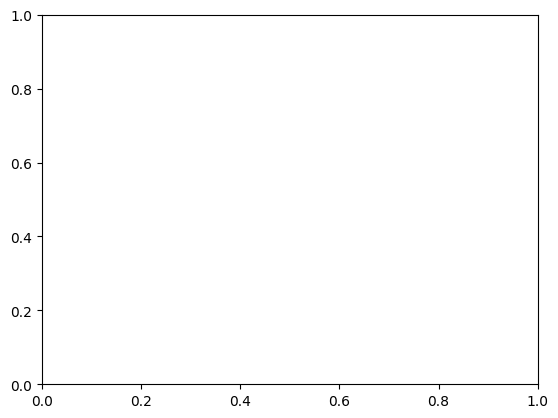

In [52]:
plt.plot(ien, vazao_media_mensal,'.')

In [ ]:
q = vazao_media_anual
q = np.array(q)

k= 1 + np.log2(len(q))

print(k)
print(len(q))
print(np.min(q).round())
print(np.max(q).round())

In [ ]:
len(limites_classes) - 1

In [ ]:
limites_classes = np.linspace(np.min(q), np.max(q), 8)

ocorrencias = np.zeros(len(limites_classes)-1)

for i in range(len(limites_classes) - 1):

    for valor in q:

        if i == len(limites_classes) - 2:

            if (valor >= limites_classes[i]) & (valor <= limites_classes[i+1]):

                ocorrencias[i] = ocorrencias[i] + 1

        else:

            if (valor >= limites_classes[i]) & (valor < limites_classes[i+1]):

                ocorrencias[i] = ocorrencias[i] + 1

In [ ]:
ocorrencias

In [ ]:
centro_classes = (limites_classes[1:] + limites_classes[:-1])/2
centro_classes

In [ ]:
ocorrencias

In [ ]:
plt.figure(figsize=(3,3))
plt.bar(centro_classes, ocorrencias, width=100)
plt.axvline(np.mean(q), color='r')
plt.xlabel('Vazão (m3/s)')
plt.ylabel('Ocorrências')

In [ ]:
plt.hist(q, 7)